# Results: Cross-fitted Text Experts vs. MulTaBench Joint TAR

This notebook compares our method (`cte_depth_top3`: cross-fitted text experts, a linear probe and depth probes on a
frozen e5-small-v2 encoder) with the baselines published by [MulTaBench](https://github.com/alanarazi7/MulTaBench).

- **Datasets:** the 20 MulTaBench text-tabular datasets, the benchmark's 5 folds (test = 10% of rows, at most 2,000).
- **Learners:** CatBoost, LightGBM, TabM, TabPFN-v2, TabPFN-2.5, each with upstream default settings.
- **Metric:** AUROC for classification (macro one-vs-rest for multiclass), R² for regression, exactly as upstream.
- **Baselines:** the leaderboard scores of the same learner, dataset and fold. **Joint TAR** fine-tunes e5 on the
  target; **Joint Frozen** uses e5 as is. TabPFN has no published baseline for Spotify Genres and Wine Review (18 datasets).

Inputs: `results/*.csv` (built by `scripts/make_results.py` from `reports/tables/fold_scores.csv`) and `reports/`.

In [1]:
import json
import os
from os.path import exists, join

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

ROOT = ".." if exists("../results") else "."
R = lambda *p: join(ROOT, *p)
FIG = R("results", "figures")
os.makedirs(FIG, exist_ok=True)

folds = pd.read_csv(R("results", "scores_per_fold.csv"))
per_ds = pd.read_csv(R("results", "scores_per_dataset.csv"))
summary = pd.read_csv(R("results", "summary.csv")).set_index("learner")
LEARNERS = ["CatBoost", "LightGBM", "TabM", "TabPFN-v2", "TabPFN-2.5"]
NAME = lambda d: d.split("_TEXT_", 1)[1].replace("_", " ").title().replace("Us ", "US ")
TASK = {"BIN": "binary", "MUL": "multiclass", "REG": "regression"}
per_ds["name"] = per_ds.dataset.map(NAME)
per_ds["task_type"] = per_ds.dataset.str[:3].map(TASK)
C_OURS, C_TAR, C_FROZEN = "#d95f02", "#1f78b4", "#b0b0b0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
print(f"{len(folds)} (learner, dataset, fold) scores; {per_ds.dataset.nunique()} datasets")

480 (learner, dataset, fold) scores; 20 datasets


## 1. Headline: our method vs. Joint TAR, with the learner held fixed

Left: each pair of bars is one learner, the mean over datasets of the leaderboard's Joint TAR score and of our score
on the same folds (the axis starts at 0.70, so the bars exaggerate the differences). Right: the same gains on their own
scale, with 95% bootstrap intervals over datasets. Means mix AUROC and R², as the benchmark's own summaries do.

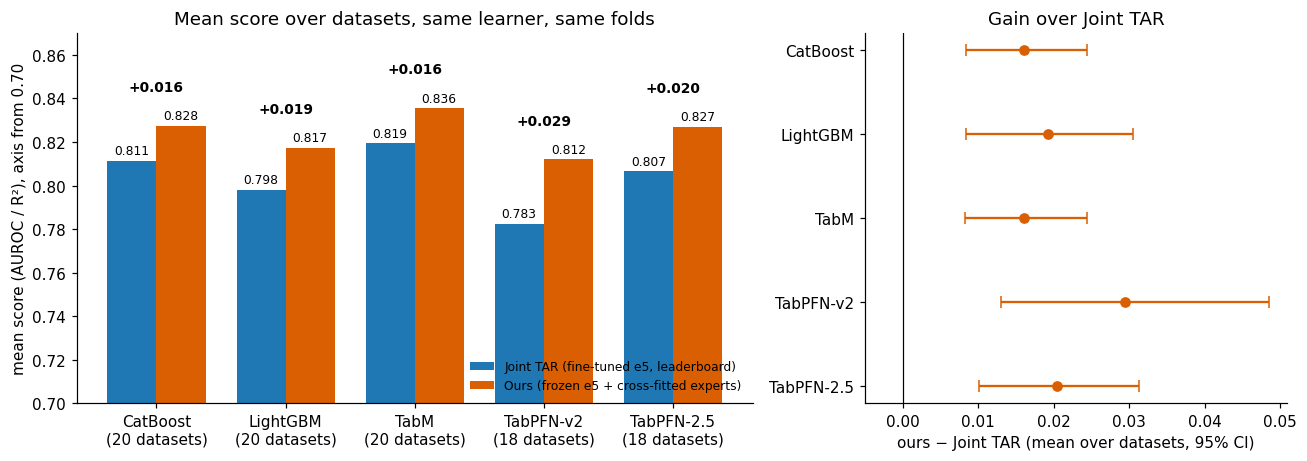

In [2]:
x = np.arange(len(LEARNERS)); w = 0.38
s = summary.loc[LEARNERS]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
ax.bar(x - w / 2, s.joint_tar, w, color=C_TAR, label="Joint TAR (fine-tuned e5, leaderboard)")
ax.bar(x + w / 2, s.ours, w, color=C_OURS, label="Ours (frozen e5 + cross-fitted experts)")
for i, (t, o) in enumerate(zip(s.joint_tar, s.ours)):
    ax.text(i - w / 2, t + 0.003, f"{t:.3f}", ha="center", fontsize=8)
    ax.text(i + w / 2, o + 0.003, f"{o:.3f}", ha="center", fontsize=8)
    ax.text(i, max(t, o) + 0.016, f"+{o - t:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x, [f"{l}\n({int(n)} datasets)" for l, n in zip(LEARNERS, s.datasets)])
ax.set_ylim(0.70, 0.87); ax.set_ylabel("mean score (AUROC / R²), axis from 0.70")
ax.set_title("Mean score over datasets, same learner, same folds")
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax2.errorbar(s.mean_gain, x, xerr=[s.mean_gain - s.ci95_low, s.ci95_high - s.mean_gain], fmt="o", color=C_OURS, capsize=4)
ax2.axvline(0, color="k", lw=0.8); ax2.set_yticks(x, LEARNERS); ax2.invert_yaxis(); ax2.set_xlim(left=-0.005)
ax2.set_xlabel("ours − Joint TAR (mean over datasets, 95% CI)"); ax2.set_title("Gain over Joint TAR")
fig.tight_layout(); fig.savefig(join(FIG, "fig1_mean_by_learner.png"), dpi=200); plt.show()

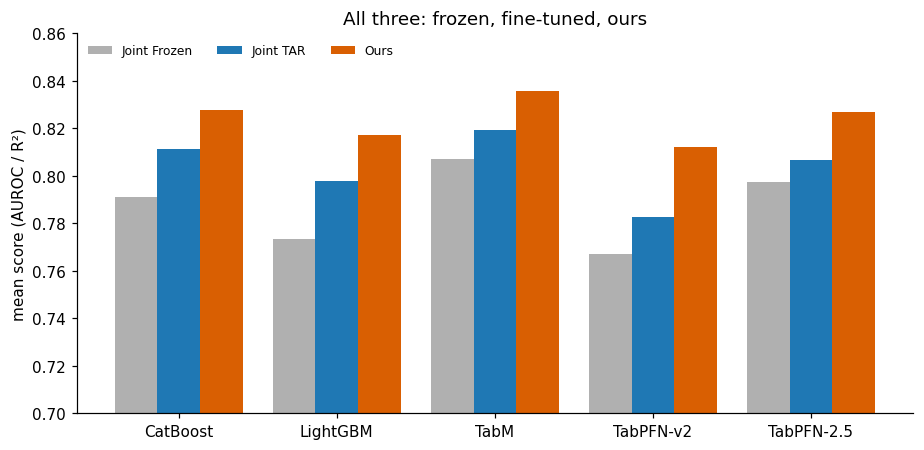

Joint TAR - Joint Frozen (what fine-tuning buys): {'CatBoost': 0.0204, 'LightGBM': 0.0246, 'TabM': 0.0122, 'TabPFN-v2': 0.0155, 'TabPFN-2.5': 0.0094}
Ours - Joint TAR: {'CatBoost': 0.0161, 'LightGBM': 0.0193, 'TabM': 0.0161, 'TabPFN-v2': 0.0294, 'TabPFN-2.5': 0.0204}
(Ours - Frozen) / (TAR - Frozen), our gain over Frozen as a multiple of fine-tuning's: {'CatBoost': 1.79, 'LightGBM': 1.79, 'TabM': 2.31, 'TabPFN-v2': 2.89, 'TabPFN-2.5': 3.18}


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.2)); w = 0.27
ax.bar(x - w, s.joint_frozen, w, color=C_FROZEN, label="Joint Frozen")
ax.bar(x, s.joint_tar, w, color=C_TAR, label="Joint TAR")
ax.bar(x + w, s.ours, w, color=C_OURS, label="Ours")
ax.set_xticks(x, LEARNERS); ax.set_ylim(0.70, 0.86); ax.set_ylabel("mean score (AUROC / R²)")
ax.set_title("All three: frozen, fine-tuned, ours")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper left")
fig.tight_layout(); fig.savefig(join(FIG, "fig1b_frozen_tar_ours.png"), dpi=200); plt.show()
gap = (s.joint_tar - s.joint_frozen)
print("Joint TAR - Joint Frozen (what fine-tuning buys):", gap.round(4).to_dict())
print("Ours - Joint TAR:", (s.ours - s.joint_tar).round(4).to_dict())
print("(Ours - Frozen) / (TAR - Frozen), our gain over Frozen as a multiple of fine-tuning's:",
      ((s.ours - s.joint_frozen) / gap).round(2).to_dict())

## 2. Statistical tests

For each learner: one number per dataset, our score minus Joint TAR averaged over the 5 folds, then a two-sided
Wilcoxon signed-rank test over datasets (do the gains lean consistently positive, or could the signs be chance?).
Each test was written down before its run. **Holm (17)** corrects across all 17 tests run in the project, the
strictest reading. The 95% interval is a bootstrap over datasets.

In [4]:
holm = json.load(open(R("reports", "p16", "p16_report.json")))["holm_all_preregistered"]
holm_key = {"CatBoost": "C9", "LightGBM": "C10_lgbm", "TabM": "C10_tabm", "TabPFN-v2": "C11_tabpfnv2",
            "TabPFN-2.5": "C11_tabpfnv2p5"}
t = s[["datasets", "joint_tar", "ours", "mean_gain", "median_gain", "ci95_low", "ci95_high", "wins", "wilcoxon_p"]].copy()
t["holm_17"] = [holm[holm_key[l]] for l in t.index]
t["passes (p < 0.05)"] = t.wilcoxon_p < 0.05
t["passes Holm (17)"] = t.holm_17 < 0.05
t

,datasets,joint_tar,ours,mean_gain,median_gain,ci95_low,ci95_high,wins,wilcoxon_p,holm_17,passes (p < 0.05),passes Holm (17)
learner,,,,,,,,,,,,
CatBoost,20,0.8114,0.8275,0.0161,0.0112,0.0084,0.0244,14,0.0023,0.0326,True,True
LightGBM,20,0.7980,0.8173,0.0193,0.0137,0.0084,0.0305,14,0.0056,0.0614,True,False
TabM,20,0.8195,0.8355,0.0161,0.0095,0.0083,0.0245,16,0.0007,0.0113,True,True
TabPFN-v2,18,0.7826,0.8120,0.0294,0.0225,0.0130,0.0485,14,0.0040,0.0481,True,True
TabPFN-2.5,18,0.8065,0.8270,0.0204,0.0124,0.0101,0.0313,15,0.0013,0.0193,True,True


## 3. Per-dataset gains

Rows are datasets (sorted by the mean gain over learners), columns are learners; each cell is our score minus Joint
TAR, averaged over the 5 folds. Orange = we are better, blue = Joint TAR is better.

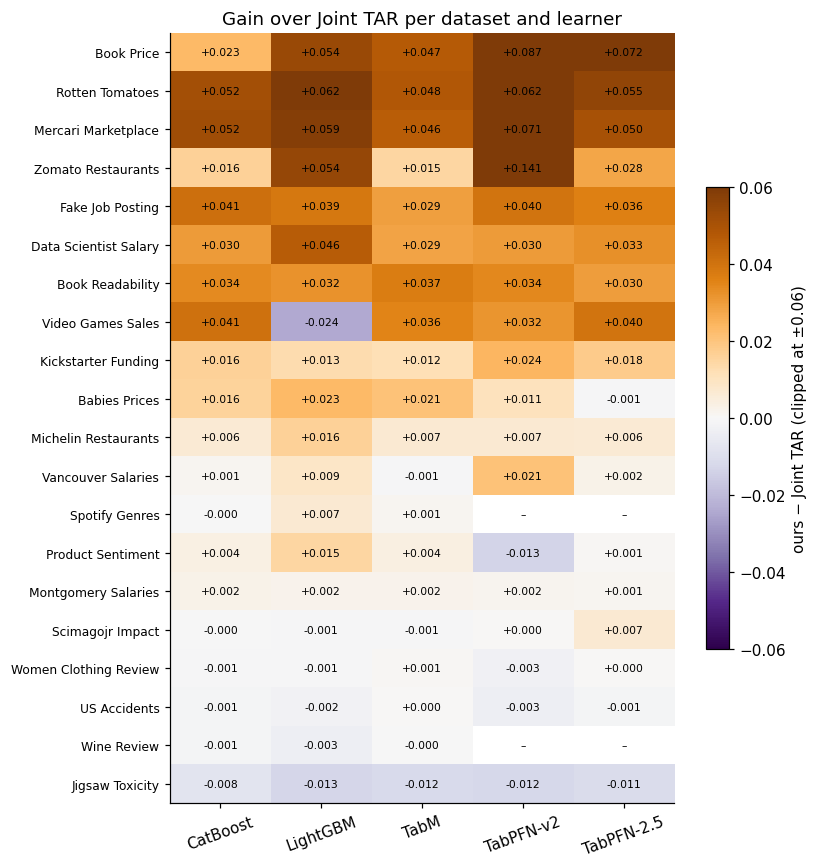

datasets where we win with every learner: 10 of 20
datasets where we lose with every learner: 2 -> ['Wine Review', 'Jigsaw Toxicity']
datasets won by >= 4 of the learners: 14


In [5]:
piv = per_ds.pivot(index="name", columns="learner", values="gain_vs_tar")[LEARNERS]
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
lim = 0.06
fig, ax = plt.subplots(figsize=(7.5, 8))
im = ax.imshow(piv.clip(-lim, lim), cmap="PuOr_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(LEARNERS)), LEARNERS, rotation=20); ax.set_yticks(range(len(piv)), piv.index, fontsize=8)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iat[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:+.3f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.6, label="ours − Joint TAR (clipped at ±0.06)")
ax.set_title("Gain over Joint TAR per dataset and learner")
fig.tight_layout(); fig.savefig(join(FIG, "fig2_gain_heatmap.png"), dpi=200); plt.show()
n_pos = (piv > 0).sum(axis=1); n_obs = piv.notna().sum(axis=1)
print("datasets where we win with every learner:", int((n_pos == n_obs).sum()), "of", len(piv))
print("datasets where we lose with every learner:", int((n_pos == 0).sum()), "->", list(piv.index[n_pos == 0]))
print("datasets won by >= 4 of the learners:", int((n_pos >= 4).sum()))

## 4. Consistency: folds, learners and noise

A mean gain can hide a few large wins. Three checks of how regular the gain is:
1. **Folds:** the share of the individual (learner, dataset, fold) runs where we beat Joint TAR.
2. **Learners:** whether the datasets we win agree across learners.
3. **Noise:** each dataset's gain against its own fold-to-fold noise in the leaderboard (`reports/phase0/baseline_noise.csv`,
   the standard deviation of paired fold differences between two baselines).

In [6]:
fl = folds.assign(win=folds.gain_vs_tar > 0)
print("runs won, per learner:", fl.groupby("learner").win.mean().loc[LEARNERS].round(3).to_dict())
print(f"all runs: {fl.win.mean():.3f} of {len(fl)}")
agree = piv.dropna().gt(0)
print("pairwise agreement of win/loss between learners (share of datasets):")
print(pd.DataFrame({a: {b: (agree[a] == agree[b]).mean() for b in LEARNERS} for a in LEARNERS}).round(2))

runs won, per learner: {'CatBoost': 0.74, 'LightGBM': 0.75, 'TabM': 0.77, 'TabPFN-v2': 0.744, 'TabPFN-2.5': 0.8}
all runs: 0.760 of 480
pairwise agreement of win/loss between learners (share of datasets):
            CatBoost  LightGBM  TabM  TabPFN-v2  TabPFN-2.5
CatBoost        1.00      0.94  0.83       0.89        0.83
LightGBM        0.94      1.00  0.78       0.83        0.78
TabM            0.83      0.78  1.00       0.72        0.78
TabPFN-v2       0.89      0.83  0.72       1.00        0.83
TabPFN-2.5      0.83      0.78  0.78       0.83        1.00


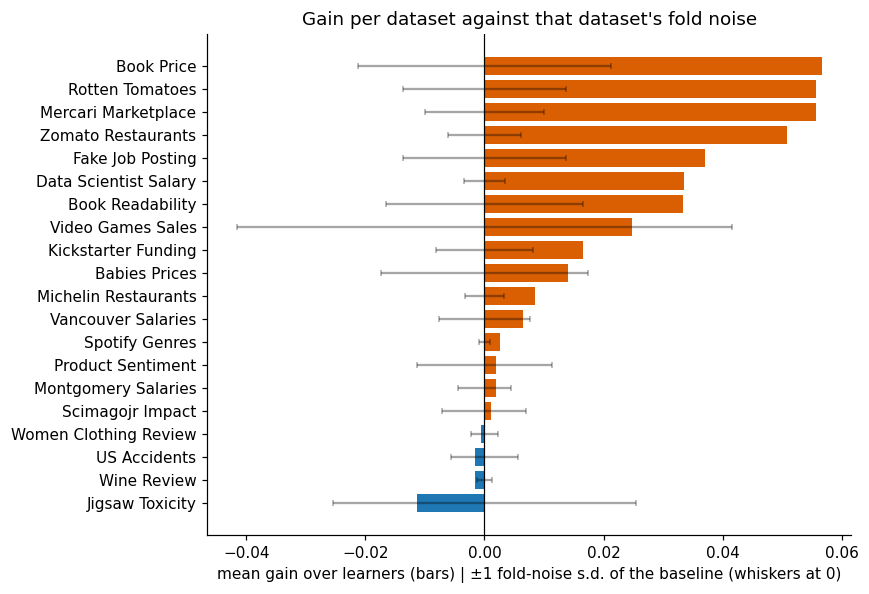

datasets whose mean gain exceeds 1 noise s.d.: 10 of 20
datasets whose mean loss exceeds 1 noise s.d.: 1


,name,mean_gain,paired_diff_std,gain_over_noise
11,Book Price,0.0567,0.0213,2.6628
15,Rotten Tomatoes,0.0558,0.0137,4.0762
13,Mercari Marketplace,0.0557,0.0101,5.5331
19,Zomato Restaurants,0.0508,0.0061,8.3751
0,Fake Job Posting,0.0370,0.0137,2.7044
3,Data Scientist Salary,0.0336,0.0035,9.5295
12,Book Readability,0.0334,0.0166,2.0114
18,Video Games Sales,0.0248,0.0416,0.5954
2,Kickstarter Funding,0.0166,0.0081,2.0525
10,Babies Prices,0.0140,0.0174,0.8055


In [7]:
noise = pd.read_csv(R("reports", "phase0", "baseline_noise.csv"))[["dataset", "paired_diff_std", "mde_paired"]]
g = per_ds.groupby("dataset").gain_vs_tar.mean().rename("mean_gain").reset_index().merge(noise, on="dataset")
g["name"] = g.dataset.map(NAME)
g["gain_over_noise"] = g.mean_gain / g.paired_diff_std
g = g.sort_values("mean_gain")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(g.name, g.mean_gain, color=[C_OURS if v > 0 else C_TAR for v in g.mean_gain])
ax.errorbar(np.zeros(len(g)), range(len(g)), xerr=g.paired_diff_std, fmt="none", ecolor="k", alpha=0.35, capsize=2)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("mean gain over learners (bars) | ±1 fold-noise s.d. of the baseline (whiskers at 0)")
ax.set_title("Gain per dataset against that dataset's fold noise")
fig.tight_layout(); fig.savefig(join(FIG, "fig3_gain_vs_noise.png"), dpi=200); plt.show()
print("datasets whose mean gain exceeds 1 noise s.d.:", int((g.gain_over_noise > 1).sum()), "of", len(g))
print("datasets whose mean loss exceeds 1 noise s.d.:", int((g.gain_over_noise < -1).sum()))
g[["name", "mean_gain", "paired_diff_std", "gain_over_noise"]].sort_values("mean_gain", ascending=False).round(4)

## 5. Where the gain comes from

**By task type**, and against **how much fine-tuning itself helps** on each dataset (Joint TAR − Joint Frozen on the
leaderboard). Fine-tuning changes the encoder; our method never does. Where the target depends on what a frozen
encoder cannot represent, fine-tuning should keep an edge.

In [8]:
by_task = per_ds.pivot_table(index="task_type", columns="learner", values="gain_vs_tar", aggfunc="mean")[LEARNERS]
by_task["datasets"] = per_ds.groupby("task_type").dataset.nunique()
by_task.round(4)

learner,CatBoost,LightGBM,TabM,TabPFN-v2,TabPFN-2.5,datasets
task_type,,,,,,
binary,0.0164,0.0129,0.0099,0.0170,0.0144,3
multiclass,0.0053,0.0111,0.0059,0.0035,0.0078,7
regression,0.0237,0.0270,0.0251,0.0461,0.0285,10


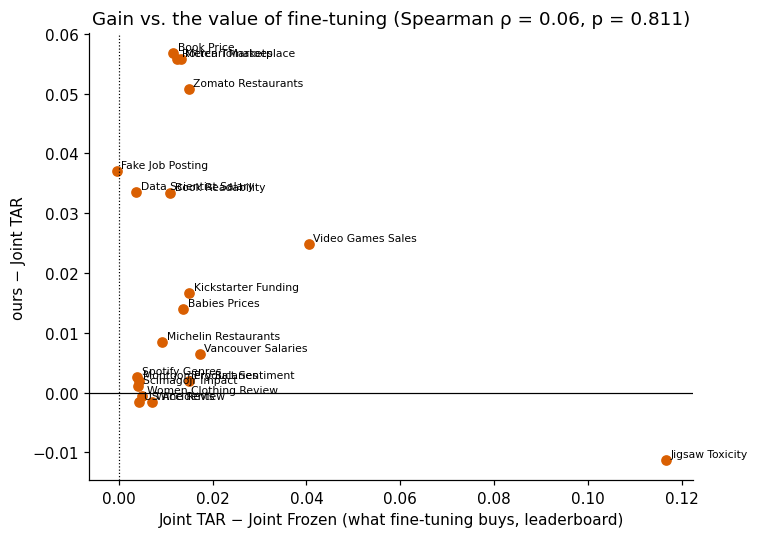

In [9]:
d = per_ds.assign(tar_gain=per_ds.joint_tar - per_ds.joint_frozen).groupby(["dataset", "name"], as_index=False)[
    ["tar_gain", "gain_vs_tar"]].mean()
rho = spearmanr(d.tar_gain, d.gain_vs_tar)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(d.tar_gain, d.gain_vs_tar, color=C_OURS)
for _, r in d.iterrows():
    ax.annotate(r["name"], (r.tar_gain, r.gain_vs_tar), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("Joint TAR − Joint Frozen (what fine-tuning buys, leaderboard)")
ax.set_ylabel("ours − Joint TAR")
ax.set_title(f"Gain vs. the value of fine-tuning (Spearman ρ = {rho.statistic:.2f}, p = {rho.pvalue:.3f})")
fig.tight_layout(); fig.savefig(join(FIG, "fig4_gain_vs_finetuning.png"), dpi=200); plt.show()

## 6. Class imbalance

Two properties of the protocol keep imbalance from distorting the comparison: the benchmark's train / test split is
**stratified** by class (tabstar `split_to_test`, `stratify=y`), so every fold keeps the dataset's class ratio, and
**AUROC does not depend on the class ratio** (it measures ranking, not a thresholded accuracy). Both methods are scored
on the same rows. Below: the class balance of each classification dataset (from the benchmark's own loader) against
our gain.

In [10]:
cb_path = R("results", "class_balance.csv")
if exists(cb_path):
    cb = pd.read_csv(cb_path)
    m = cb.merge(per_ds.groupby("dataset").gain_vs_tar.mean().rename("mean_gain").reset_index(), on="dataset")
    m["name"] = m.dataset.map(NAME)
    display(m[["name", "n_classes", "minority_share", "majority_share", "mean_gain"]].sort_values("minority_share").round(4))
    r = spearmanr(m.minority_share, m.mean_gain)
    print(f"Spearman(minority share, mean gain) = {r.statistic:.2f} (p = {r.pvalue:.2f}, n = {len(m)})")
else:
    print("results/class_balance.csv not found (scripts/class_balance.py builds it; needs the datasets locally)")

,name,n_classes,minority_share,majority_share,mean_gain
8,Wine Review,30,0.0080,0.1262,-0.0017
4,Michelin Restaurants,5,0.0083,0.6138,0.0085
7,US Accidents,4,0.0087,0.7967,-0.0015
6,Spotify Genres,114,0.0088,0.0088,0.0027
5,Product Sentiment,4,0.0191,0.5926,0.0019
9,Women Clothing Review,5,0.0366,0.5555,-0.0006
0,Fake Job Posting,2,0.0433,0.9567,0.0370
1,Jigsaw Toxicity,2,0.0604,0.9396,-0.0113
3,Data Scientist Salary,6,0.0786,0.2278,0.0336
2,Kickstarter Funding,2,0.3196,0.6804,0.0166


Spearman(minority share, mean gain) = 0.42 (p = 0.23, n = 10)


## 7. What each part contributes

**Build-up** (CatBoost, all 20 datasets, 5 folds, each vs. Joint TAR of the same fold): each expert alone, the lexical
expert *without* cross-fitting, the experts together, then the probe and the depth probes added. All rows are full
benchmark runs (`reports/tables/fold_scores.csv`). **Depth profile**: for all 20 datasets, how well a cross-fitted
linear probe on each of e5's 12 layers predicts the target, minus the final-layer probe (out-of-fold scores on the
training rows of the final CatBoost run, averaged over the 5 folds; `scripts/depth_figures.py`). The dot marks each
dataset's best layer. Colours are clipped at ±0.03 (Book Readability exceeds the scale: +0.055 at layer 3).

,stage,datasets,mean_gain_vs_tar,wins,wilcoxon_p
0,Joint Frozen (leaderboard),20,-0.0204,0,0.0000
1,our Joint TAR re-implementation,20,-0.0017,6,0.0532
2,numeracy features only,20,-0.0108,3,0.0073
3,neighbour expert only,20,-0.0064,5,0.0826
4,"lexical expert, NOT cross-fitted",20,-0.0345,1,0.0001
5,lexical expert only,20,-0.0000,8,0.7285
6,all experts (CTE),20,0.0106,11,0.0583
7,+ probe on the full embedding,20,0.0141,15,0.0023
8,+ depth probes = final method,20,0.0161,14,0.0023


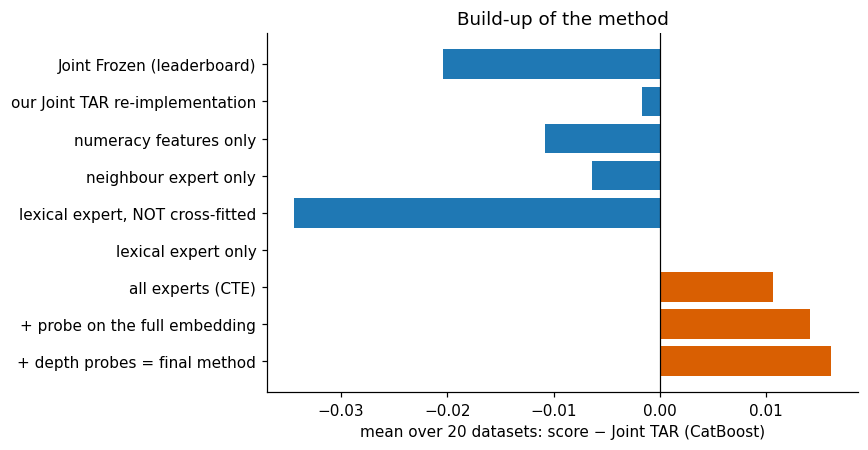

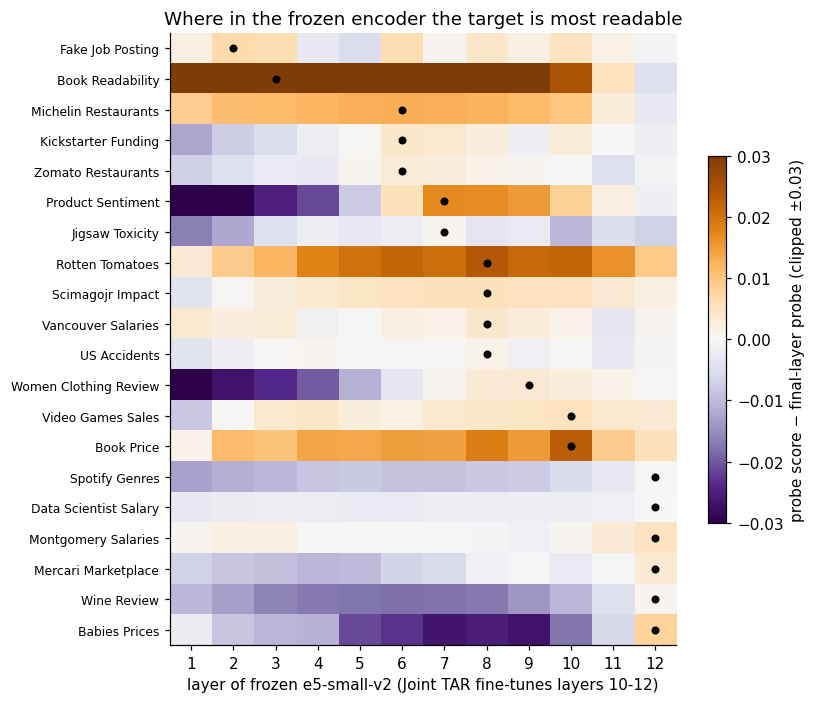

best layer per dataset: {2: 1, 3: 1, 6: 3, 7: 2, 8: 4, 9: 1, 10: 2, 12: 6}
datasets whose best layer is an inner one (< 12): 14 of 20
largest inner-layer gains: {'Book Readability': 0.0545, 'Rotten Tomatoes': 0.0239, 'Book Price': 0.0231, 'Product Sentiment': 0.0171}


In [11]:
fs = pd.read_csv(R("reports", "tables", "fold_scores.csv"))
STAGES = [("Joint Frozen (leaderboard)", None), ("our Joint TAR re-implementation", "tar_repro"),
          ("numeracy features only", "cte_num"), ("neighbour expert only", "cte_nbr"),
          ("lexical expert, NOT cross-fitted", "cte_lex_insample"), ("lexical expert only", "cte_lex"),
          ("all experts (CTE)", "cte"), ("+ probe on the full embedding", "cte_probe"),
          ("+ depth probes = final method", "cte_depth_top3")]
cb = fs[(fs.learner == "catboost") & fs.dataset.isin(per_ds.dataset.unique())]
rows = []
for label, m in STAGES:
    d_ = cb[cb.method == "cte"] if m is None else cb[cb.method == m]
    diff = (d_.lb_joint_frozen if m is None else d_.score) - d_.lb_joint_tar
    by = diff.groupby(d_.dataset).mean()
    rows.append({"stage": label, "datasets": by.size, "mean_gain_vs_tar": by.mean(), "wins": int((by > 0).sum()),
                 "wilcoxon_p": wilcoxon(by).pvalue})
bu = pd.DataFrame(rows)
display(bu.round(4))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(bu.stage, bu.mean_gain_vs_tar, color=[C_OURS if v > 0 else C_TAR for v in bu.mean_gain_vs_tar])
ax.axvline(0, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("mean over 20 datasets: score − Joint TAR (CatBoost)"); ax.set_title("Build-up of the method")
fig.tight_layout(); fig.savefig(join(FIG, "fig5a_build_up.png"), dpi=200); plt.show()
dp = pd.read_csv(R("reports", "figures", "fig7_depth_profile_20.csv"))
hm = dp.pivot(index="dataset", columns="layer", values="delta")
best = hm.idxmax(axis=1)
hm = hm.loc[best.sort_values().index]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
lim = 0.03
im = ax.imshow(hm.clip(-lim, lim), cmap="PuOr_r", vmin=-lim, vmax=lim, aspect="auto")
ax.scatter(hm.idxmax(axis=1).to_numpy() - 1, range(len(hm)), s=18, color="k")
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(len(hm)), [NAME(d) for d in hm.index], fontsize=8)
ax.set_xlabel("layer of frozen e5-small-v2 (Joint TAR fine-tunes layers 10-12)")
fig.colorbar(im, ax=ax, shrink=0.6, label="probe score − final-layer probe (clipped ±0.03)")
ax.set_title("Where in the frozen encoder the target is most readable")
fig.tight_layout(); fig.savefig(join(FIG, "fig5_depth_profile.png"), dpi=200); plt.show()
print("best layer per dataset:", best.value_counts().sort_index().to_dict())
print("datasets whose best layer is an inner one (< 12):", int((best < 12).sum()), "of", len(best))
print("largest inner-layer gains:", hm.max(axis=1).sort_values(ascending=False).head(4).round(4).rename(index=NAME).to_dict())

## 8. Cost of building the text features

Joint TAR fine-tunes e5 on a GPU; our method builds its features on the CPU. Both timed on the same Colab A100
machine, per (dataset, fold) (`scripts/compute_cost.py`). Joint TAR's time is our fast re-implementation of its
fine-tuning, about 11× faster per epoch than upstream's own code; our time is a run in which every expert and probe
was built from scratch.

In [12]:
cc = pd.read_csv(R("results", "compute_cost.csv"))
ct = cc.groupby("dataset")[["tar_seconds", "ours_seconds"]].mean().div(60).rename(
    columns={"tar_seconds": "Joint TAR fine-tuning, GPU (min)", "ours_seconds": "ours, CPU (min)"})
ct.index = ct.index.map(NAME)
display(ct.sort_values("ours, CPU (min)").round(2))
print(f"median per job: Joint TAR {cc.tar_seconds.median() / 60:.1f} min (GPU), ours {cc.ours_seconds.median() / 60:.1f} min (CPU)")

,"Joint TAR fine-tuning, GPU (min)","ours, CPU (min)"
dataset,,
Product Sentiment,0.27,0.33
Babies Prices,1.28,1.12
Video Games Sales,0.79,1.18
Vancouver Salaries,0.57,1.26
Book Price,1.28,1.53
Book Readability,1.73,1.60
Women Clothing Review,0.71,1.61
Jigsaw Toxicity,0.63,2.07
Montgomery Salaries,1.11,2.07


median per job: Joint TAR 1.3 min (GPU), ours 2.7 min (CPU)


**Reading.** Our method is not faster than an optimised fine-tuning: about 2× its time per job, on a CPU instead of a
GPU. What it saves is the GPU. It also builds features once per (dataset, fold) for all learners that share the same
training rows, whereas upstream's Joint TAR fine-tunes again inside every learner's run.

## 9. Beyond the 20: 36 further text datasets

To check that the method was not tuned to the 20 benchmark datasets, it was run once (CatBoost, folds 0–2) on 36
further text datasets that have MulTaBench baselines (`multabench/leaderboard/results/text_source/`) and were never
used during development. The **median** is the summary to read: on two used-car price datasets with heavy-tailed
targets (Mercedes-Benz Italy, CarDekho) both methods score R² far below zero on some folds, and the difference of two
broken scores (+11.96 on Mercedes-Benz) dominates the mean.

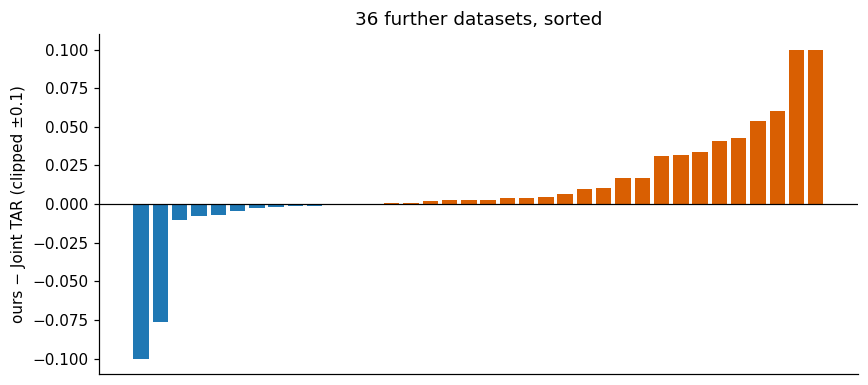

n = 36, wins = 24, median +0.0027, Wilcoxon p = 0.0168, Holm (17) = 0.138
mean +0.3451; without the two heavy-tailed car-price datasets +0.0032


In [13]:
c7 = json.load(open(R("reports", "p14", "p14_report.json")))["C7"]["cte_depth_top3|vs_joint_tar"]
h = pd.Series(c7["per_dataset"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(h)), h.clip(-0.1, 0.1), color=[C_OURS if v > 0 else C_TAR for v in h])
ax.axhline(0, color="k", lw=0.8); ax.set_xticks([])
ax.set_ylabel("ours − Joint TAR (clipped ±0.1)"); ax.set_title("36 further datasets, sorted")
fig.tight_layout(); fig.savefig(join(FIG, "fig6_36_datasets.png"), dpi=200); plt.show()
holm7 = json.load(open(R("reports", "p16", "p16_report.json")))["holm_all_preregistered"]["C7:cte_depth_top3|vs_joint_tar"]
print(f"n = {c7['n']}, wins = {c7['wins']}, median {c7['median_diff']:+.4f}, Wilcoxon p = {c7['p_value']:.4f}, "
      f"Holm (17) = {holm7:.3f}")
heavy = ["REG_TEXT_TRANSPORTATION_USED_CAR_MERCEDES_BENZ_ITALY", "REG_TEXT_CONSUMER_CAR_PRICE_CARDEKHO"]
print(f"mean {c7['mean_diff']:+.4f}; without the two heavy-tailed car-price datasets {h.drop(heavy).mean():+.4f}")

## 10. Trust checks

- **Label shuffle.** The whole method retrained with the training labels randomly permuted (true test labels kept,
  development split of training rows). If any label information reached the features by another path, the score would
  stay high; it falls to chance.
- **Independent recomputation.** `scripts/check_recompute.py` recomputes every headline number from the raw result
  files and the leaderboard CSVs with no project code; it reproduces all 5 rows of section 2.
- **Same benchmark.** Upstream code at tag `paper_version`, unmodified; for these 20 datasets its splits, metrics,
  preprocessing and baseline scores are identical to upstream `master` of 26 July 2026.
- **Same environment.** Our own re-implementation of Joint TAR, run in our environment, scores 0.0017 below the
  published numbers (6 of 20 datasets higher, p = 0.053; section 7). If our environment differs from the authors' at
  all, it lowers scores, which makes the comparison with the published baselines harder for our method, not easier.

In [14]:
pd.read_csv(R("reports", "checks", "label_shuffle.csv")).round(4)

,dataset,method,train_labels,perm_seed,score,seconds
0,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,true,NaN,0.7634,362.1
1,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,NaN,0.5326,319.6
2,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3,true,NaN,0.9065,16.2
3,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3,shuffled,NaN,0.4857,13.1
4,REG_TEXT_BOOK_PRICE,cte_depth_top3,true,NaN,0.5640,75.9
5,REG_TEXT_BOOK_PRICE,cte_depth_top3,shuffled,NaN,-0.0081,92.9
6,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,1.0,0.5066,279.9
7,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,2.0,0.5218,415.0
8,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,3.0,0.5001,305.2


**Not a lucky seed.** The method's own randomness is the assignment of training rows to the 5 cross-fitting folds
(seed 42 everywhere above; the learners' seeds are fixed by the benchmark). LightGBM was re-run with fold seeds 43 and
44 (`reports/p17/`, specified before the run, Holm over the two seeds). Below: the gain per seed, then per dataset.

In [15]:
p17 = json.load(open(R("reports", "p17", "p17_report.json")))
runs = {"seed 42": p17["seed42_C10"], "seed 43": p17["C12"]["seed43"], "seed 44": p17["C12"]["seed44"]}
display(pd.DataFrame({k: {"mean gain": c["mean_diff"], "median gain": c["median_diff"], "wins": c["wins"], "p": c["p_value"],
                          "Holm (2 seeds)": c.get("p_holm")} for k, c in runs.items()}).T.round(4))
sd = pd.DataFrame({k: c["per_dataset"] for k, c in runs.items()})
sd.index = sd.index.map(NAME)
sd["sd over seeds"] = sd.std(axis=1, ddof=1)
print(f"per-dataset sd of the gain over the 3 seeds: median {sd['sd over seeds'].median():.4f}, "
      f"max {sd['sd over seeds'].max():.4f} ({sd['sd over seeds'].idxmax()})")
sd.sort_values("sd over seeds", ascending=False).head(5).round(4)

,mean gain,median gain,wins,p,Holm (2 seeds)
seed 42,0.0193,0.0137,14.0,0.0056,NaN
seed 43,0.0169,0.0140,15.0,0.0094,0.0189
seed 44,0.0176,0.0129,15.0,0.0107,0.0189


per-dataset sd of the gain over the 3 seeds: median 0.0013, max 0.0182 (Video Games Sales)


,seed 42,seed 43,seed 44,sd over seeds
Video Games Sales,-0.0240,-0.0583,-0.0517,0.0182
Book Price,0.0535,0.0446,0.0448,0.0051
Babies Prices,0.0231,0.0262,0.0327,0.0049
Vancouver Salaries,0.0086,0.0038,0.0029,0.0031
Book Readability,0.0320,0.0298,0.0336,0.0019


## 11. Summary

1. **Better than Joint TAR with every learner.** The mean gain is +0.016 to +0.029 (AUROC / R²). Measured from Joint
   Frozen, our method adds 1.8× (CatBoost, LightGBM) to 3.2× (TabPFN-2.5) what fine-tuning adds, without fine-tuning.
2. **Significant for all 5 learners** (two-sided Wilcoxon over datasets, p ≤ 0.0056); **4 of 5 also survive** the
   Holm correction over all 17 tests of the project (LightGBM: 0.061).
3. **Broad, not driven by a few datasets.** 76% of the 480 individual runs beat Joint TAR; 10 of the 20 datasets are
   won with every learner and 14 with at least 4; the learners agree on win / loss for 72–94% of the datasets.
4. **Above the noise.** On 10 of the 20 datasets the mean gain exceeds one standard deviation of the baseline's own
   fold-to-fold noise; only Wine Review loses by more than that, and by 0.002.
5. **Largest on regression** (+0.024 to +0.046), then binary (+0.010 to +0.017), smallest on multiclass (+0.004 to +0.011).
6. **The target sits at different depths**: the best probe layer ranges from 2 to 12 and is an inner layer in 14 of
   the 20 datasets (largest gain: Book Readability, layer 3), which is what the depth probes exploit.
7. **Where fine-tuning still wins: Jigsaw Toxicity**, the one dataset where fine-tuning itself adds +0.117 over the
   frozen encoder; toxicity is not linearly readable from frozen e5. Elsewhere our gain is unrelated to how much
   fine-tuning helps (Spearman ρ = 0.06).
8. **Class imbalance does not drive the result**: the gain is unrelated to the minority-class share (ρ = 0.42,
   p = 0.23, 10 datasets), splits are stratified, and AUROC does not depend on the class ratio.
9. **Cross-fitting is essential**: the same lexical expert without it scores 0.034 lower (−0.034 vs. Joint TAR
   instead of ±0.000), and 0.045 below the full set of cross-fitted experts.
10. **On 36 further datasets** the gain is positive but small (median +0.003, 24 of 36 won); significant on its own
   (p = 0.017), not after the 17-test correction.
11. **No GPU needed, but not faster**: building our features takes about 2.7 min per job on a CPU, against 1.3 min for
    an optimised GPU fine-tuning of Joint TAR.
12. **No leakage path found**: with shuffled training labels the method falls to chance (AUROC 0.50–0.53, R² −0.01).
13. **Not a lucky seed**: with two other cross-fitting fold seeds (LightGBM) the gain is +0.017 and +0.018 (15 of 20
    datasets each, Holm p = 0.019); per dataset it moves by a median 0.001 between seeds, most on Video Games Sales.